# 03 · Model Development, Validation & Business Impact

This notebook analyses the results of the full training pipeline (`python -m src.pipeline`) on the four C-MAPSS scenarios and runs additional experiments (feature ablation, cost sensitivity).

**Validation protocol (leakage-safe)**

| Set | Content | Use |
|---|---|---|
| Training engines (80 %) | full run-to-failure trajectories, every 2nd cycle | fitting, engine-grouped 3-fold CV for hyper-parameter search, 5-fold OOF for stacking |
| Validation engines (20 %) | 10 random truncation points per engine | model selection, conformal calibration, isotonic decision |
| Validation engines (full trajectories) | every cycle | maintenance-policy simulation |
| Official NASA test set | last cycle of every test engine | final, untouched evaluation |

Engines never appear on both sides of a split; all features are causal.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from src.utils import load_config
from src.utils import visualization as viz
from src.models.train import MODEL_LABELS
from src.models.predict import load_predictor

cfg = load_config(ROOT / "config.yaml")
viz.set_style()
FIG, MET = ROOT / cfg["paths"]["figures_dir"], ROOT / "reports" / "metrics"
val = pd.read_csv(MET / "validation_metrics.csv")
test = pd.read_csv(MET / "test_metrics.csv")
tuning = pd.read_csv(MET / "tuning_results.csv")
policies = pd.read_csv(MET / "maintenance_policies.csv")
summary = json.loads((MET / "summary.json").read_text())
pd.set_option("display.precision", 3)

## 1. Hyper-parameter optimisation

Randomised search (12 candidates × 3 engine-grouped folds) over HistGradientBoosting. The health indicator and feature selector are refitted in every fold; a `joblib.Memory` cache avoids refitting them for every candidate.

,dataset,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features,cv_rmse,cv_nasa_score
24,FD003,0.043,330,15,80,0.297,0.5,10.709,6207.005
25,FD003,0.027,658,15,160,0.004,1.0,10.860,6244.662
26,FD003,0.079,234,31,20,0.009,0.5,10.895,6443.631
0,FD001,0.043,330,15,80,0.297,0.5,11.781,6929.421
1,FD001,0.074,543,31,40,0.004,0.5,11.900,7215.734
2,FD001,0.021,755,31,40,0.187,0.8,11.949,7381.561
12,FD002,0.043,330,15,80,0.297,0.5,13.019,21955.160
36,FD004,0.021,755,31,40,0.187,0.8,13.047,53585.379
37,FD004,0.043,330,15,80,0.297,0.5,13.109,62204.857
13,FD002,0.027,658,15,160,0.004,1.0,13.131,22178.146


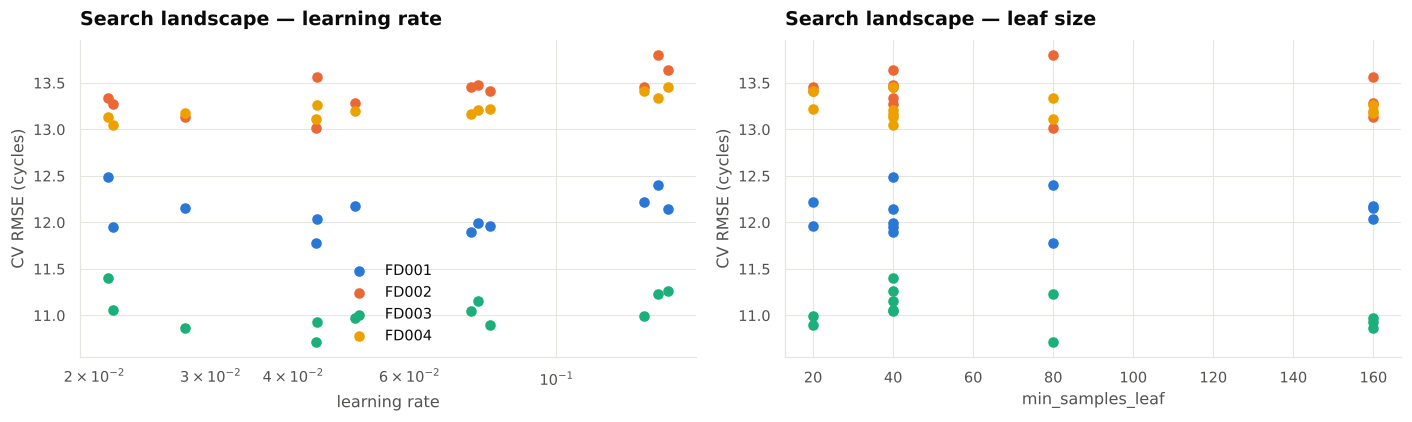

In [2]:
best = tuning.sort_values("cv_rmse").groupby("dataset").head(3)
display(best[["dataset", "learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf",
              "l2_regularization", "max_features", "cv_rmse", "cv_nasa_score"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, (name, grp) in enumerate(tuning.groupby("dataset")):
    axes[0].scatter(grp["learning_rate"], grp["cv_rmse"], color=viz.PALETTE[i], label=name, s=35)
    axes[1].scatter(grp["min_samples_leaf"].astype(float), grp["cv_rmse"], color=viz.PALETTE[i], label=name, s=35)
axes[0].set(xscale="log", xlabel="learning rate", ylabel="CV RMSE (cycles)", title="Search landscape — learning rate")
axes[1].set(xlabel="min_samples_leaf", ylabel="CV RMSE (cycles)", title="Search landscape — leaf size")
axes[0].legend(); fig.tight_layout(); plt.show()

## 2. Model comparison across the four scenarios

In [3]:
order = ["ridge", "random_forest", "extra_trees", "hgb_default", "hgb_tuned", "stacking", "production"]
tbl = (test.pivot(index="model", columns="dataset", values="rmse").reindex(order)
       .rename(index={**MODEL_LABELS, "production": "Production bundle"}))
nasa = (test.pivot(index="model", columns="dataset", values="nasa_score").reindex(order)
        .rename(index={**MODEL_LABELS, "production": "Production bundle"}))
print("Official test set — RMSE (cycles)"); display(tbl.round(2))
print("Official test set — NASA asymmetric score (lower is better)"); display(nasa.round(0))
prod = test[test.model == "production"].set_index("dataset")
display(prod[["rmse", "mae", "r2", "nasa_score", "phm_accuracy", "late_rate", "c_index",
              "alert_precision", "alert_recall", "coverage", "mean_width"]].round(3))
print({d: summary[d]["production_model"] for d in summary})

Official test set — RMSE (cycles)


dataset,FD001,FD002,FD003,FD004
model,,,,
Ridge (linear baseline),16.26,15.82,15.82,18.45
Random Forest,12.51,12.46,13.10,14.03
Extra Trees,12.64,12.28,13.47,14.37
HistGradientBoosting (default),12.23,12.40,11.12,13.45
HistGradientBoosting (tuned),12.14,12.32,11.29,13.25
Stacking ensemble,12.19,12.22,11.70,13.26
Production bundle,12.19,12.40,11.29,13.25


Official test set — NASA asymmetric score (lower is better)


dataset,FD001,FD002,FD003,FD004
model,,,,
Ridge (linear baseline),404.0,1038.0,428.0,1789.0
Random Forest,249.0,691.0,332.0,1000.0
Extra Trees,250.0,656.0,392.0,1051.0
HistGradientBoosting (default),248.0,702.0,247.0,901.0
HistGradientBoosting (tuned),242.0,666.0,256.0,873.0
Stacking ensemble,250.0,663.0,276.0,885.0
Production bundle,250.0,702.0,256.0,873.0


,rmse,mae,r2,nasa_score,phm_accuracy,late_rate,c_index,alert_precision,alert_recall,coverage,mean_width
dataset,,,,,,,,,,,
FD001,12.189,9.071,0.907,249.580,0.710,0.200,0.879,1.000,0.840,0.820,28.612
FD002,12.399,8.803,0.917,702.346,0.707,0.189,0.907,0.984,0.984,0.826,27.603
FD003,11.292,7.298,0.917,256.140,0.790,0.150,0.918,0.950,0.950,0.740,25.247
FD004,13.249,8.780,0.905,872.554,0.726,0.177,0.909,0.941,0.906,0.802,30.731


{'FD001': 'stacking', 'FD002': 'hgb_default', 'FD003': 'hgb_tuned', 'FD004': 'hgb_tuned'}


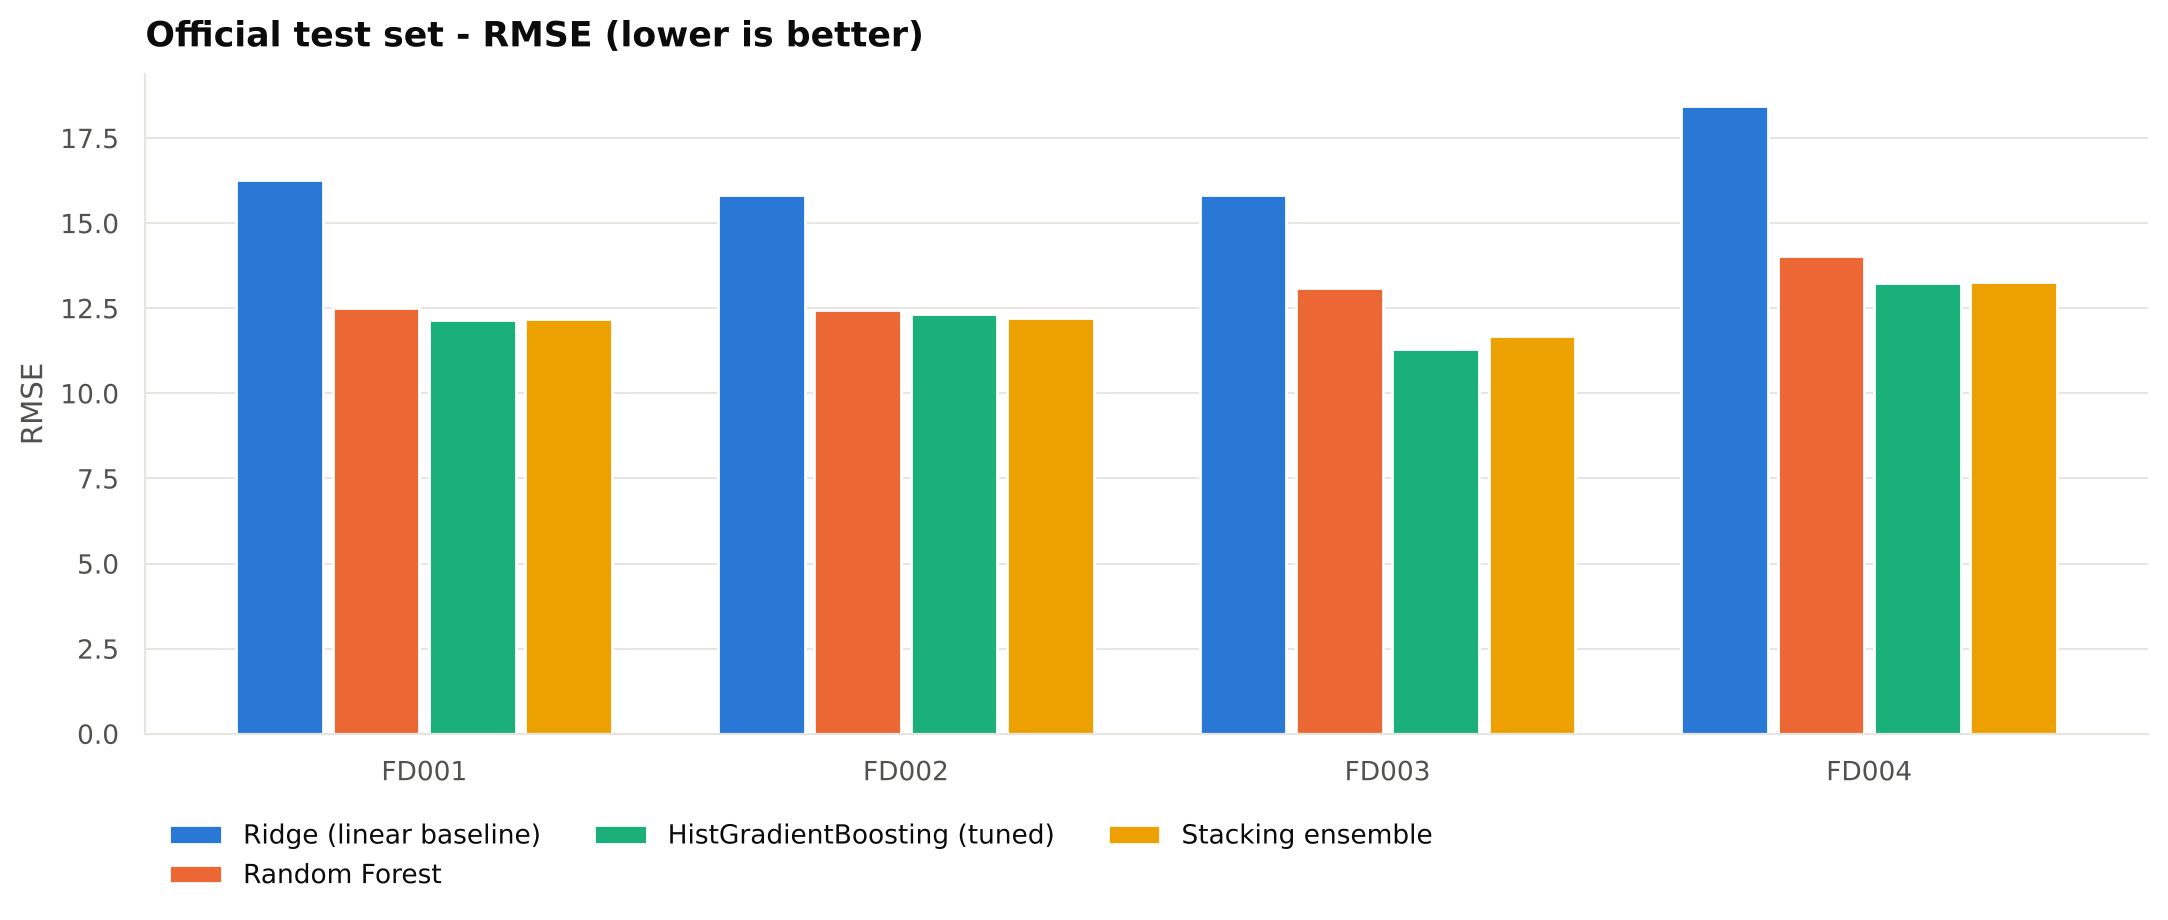

In [4]:
display(Image(FIG / "model_comparison_rmse.png", width=900))

**Reading the results**

* Tree ensembles beat the linear baseline by **3.6–5.2 cycles of RMSE** in every scenario; the gap is largest on the two-fault-mode datasets (FD003/FD004), where the opposite sensor signatures of the two modes cannot be captured linearly.
* **Gradient boosting is the strongest family**; tuned HGB, default HGB and stacking are within ~0.5 cycle of each other everywhere. Validation-based selection picked stacking for FD001 and HGB elsewhere — with gaps of a few tenths of a cycle, the honest reading is that these three are statistically tied, and the simpler model is preferable when it is selected.
* Thanks to regime normalisation, the six-regime **FD002 is as accurate as the single-regime FD001** (12.4 vs 12.2). FD004 (six regimes *and* two fault modes) is the hardest scenario at 13.2 cycles.
* FD002/FD004 have much higher NASA scores in absolute terms mainly because they contain ~2.5× more test engines (the score is a sum); per engine the score is 2.5–2.7 for FD001–FD003 and 3.5 for FD004.
* **C-index 0.88–0.92**: in about 9 out of 10 engine pairs the model correctly ranks which engine fails first — the property that matters most for fleet-level maintenance planning.
* Alert precision/recall at 30 cycles ≥ 0.84 on every scenario.

### Does validation predict test performance?

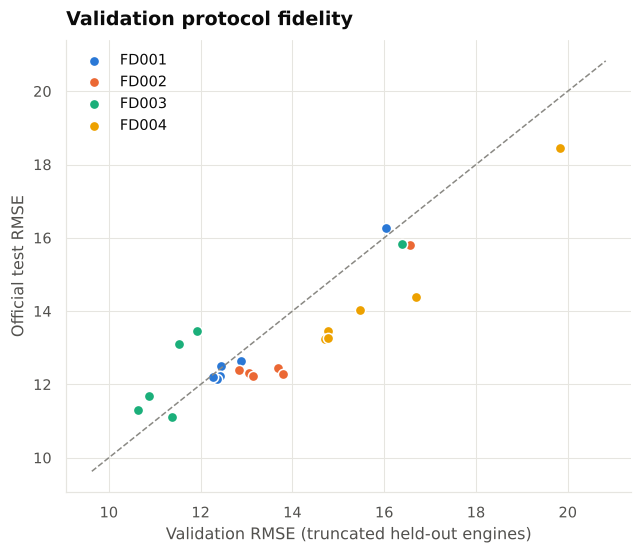

Spearman rank correlation val vs test RMSE: 0.81


In [5]:
cmp = val.merge(test, on=["dataset", "model"], suffixes=("_val", "_test"))
fig, ax = plt.subplots(figsize=(6, 5.2))
for i, (name, grp) in enumerate(cmp.groupby("dataset")):
    ax.scatter(grp["rmse_val"], grp["rmse_test"], color=viz.PALETTE[i], s=45, label=name, edgecolor="white")
lim = [cmp[["rmse_val", "rmse_test"]].min().min() - 1, cmp[["rmse_val", "rmse_test"]].max().max() + 1]
ax.plot(lim, lim, color=viz.INK_3, ls="--", lw=1)
ax.set(xlabel="Validation RMSE (truncated held-out engines)", ylabel="Official test RMSE",
       title="Validation protocol fidelity"); ax.legend()
fig.tight_layout(); viz.save_figure(fig, "validation_vs_test", FIG); plt.show()
print("Spearman rank correlation val vs test RMSE:", round(cmp[["rmse_val", "rmse_test"]].corr("spearman").iloc[0, 1], 3))

The truncation-based validation tracks the official test set closely, so model selection on validation is trustworthy (and the test set was never used for any decision).

### Stacking meta-learner weights

In [6]:
weights = {}
bundles = {d: load_predictor(d, ROOT / "models") for d in summary}
for d, b in bundles.items():
    est = b.model_pipeline[-1]
    if hasattr(est, "final_estimator_"):
        weights[d] = pd.Series(est.final_estimator_.coef_, index=list(est.named_estimators_))
pd.DataFrame(weights).round(3)

,FD001
ridge,0.000
random_forest,0.013
extra_trees,0.123
hgb,0.876


## 3. Feature ablation (FD001)

How much does each feature family contribute? The tuned HistGradientBoosting configuration is retrained on nested feature sets and evaluated on the official test set.

00:39:03 | INFO    | src.data.load_data | Loaded FD001: 100 train engines (20631 rows), 100 test engines (13096 rows)


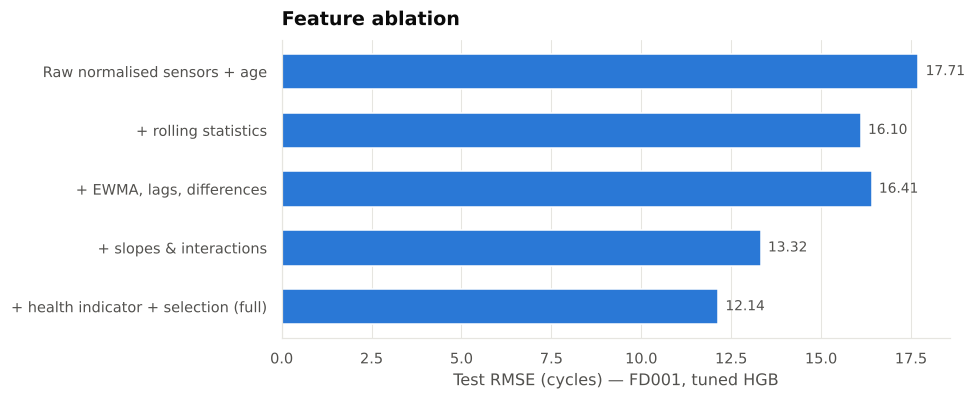

,feature set,n_features,test RMSE,NASA score
0,Raw normalised sensors + age,15,17.71,647.89
1,+ rolling statistics,351,16.10,436.10
2,"+ EWMA, lags, differences",463,16.41,460.54
3,+ slopes & interactions,511,13.32,310.35
4,+ health indicator + selection (full),120,12.14,241.99


In [7]:
from src.data.load_data import load_dataset
from src.data.preprocess import add_train_rul, add_test_rul, split_engines, subsample_rows, last_cycle_rows
from src.features.engineering import build_feature_pipeline
from src.models.train import make_regressor, build_model_pipeline
from src.utils.metrics import rmse, nasa_score

SEED, MAX_RUL = cfg["project"]["random_seed"], cfg["target"]["max_rul"]
ds = load_dataset("FD001", ROOT / cfg["paths"]["raw_dir"])
tr, _ = split_engines(add_train_rul(ds.train, MAX_RUL), cfg["split"]["validation_fraction"], SEED)
te = add_test_rul(ds.test, ds.test_rul, MAX_RUL)
fp = build_feature_pipeline(cfg, 1).fit(tr)
Ftr, Fte = fp.transform(tr), fp.transform(te)
idx = subsample_rows(tr, 2).index
Xtr, ytr = Ftr.loc[idx], tr.loc[idx, "rul"].to_numpy()
last = last_cycle_rows(te).index
Xte, yte = Fte.loc[last], te.loc[last, "rul"].to_numpy()
params = bundles["FD001"].metadata["hgb_params"]
S = cfg["data"]["sensors"]
sets = {
    "Raw normalised sensors + age": ["unit", "cycle"] + S,
    "+ rolling statistics": lambda c: "_roll" in c,
    "+ EWMA, lags, differences": lambda c: any(k in c for k in ["_ewm", "_lag", "_diff"]),
    "+ slopes & interactions": lambda c: "_slope" in c or c.startswith("ix_"),
}
cols, rows = [], []
for label, rule in sets.items():
    cols = rule if isinstance(rule, list) else cols + [c for c in Ftr.columns if rule(c)]
    model = make_regressor("hgb", cfg, SEED, params).fit(Xtr[cols], ytr)
    pred = np.clip(model.predict(Xte[cols]), 0, MAX_RUL)
    rows.append({"feature set": label, "n_features": len(cols) - 1, "test RMSE": rmse(yte, pred), "NASA score": nasa_score(yte, pred)})
full = build_model_pipeline(cfg, make_regressor("hgb", cfg, SEED, params), SEED).fit(Xtr, ytr)
pred = np.clip(full.predict(Xte), 0, MAX_RUL)
rows.append({"feature set": "+ health indicator + selection (full)", "n_features": len(full.named_steps["selector"].selected_features_),
             "test RMSE": rmse(yte, pred), "NASA score": nasa_score(yte, pred)})
ablation = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(ablation["feature set"][::-1], ablation["test RMSE"][::-1], color=viz.PALETTE[0], height=0.6)
for i, v in enumerate(ablation["test RMSE"][::-1]):
    ax.text(v + 0.2, i, f"{v:.2f}", va="center", fontsize=9, color=viz.INK_2)
ax.set(xlabel="Test RMSE (cycles) — FD001, tuned HGB", title="Feature ablation"); ax.grid(axis="y", visible=False)
fig.tight_layout(); viz.save_figure(fig, "ablation_FD001", FIG); plt.show()
ablation.round(2)

**Ablation findings (FD001, test set)**
* Rolling statistics bring the first big gain (17.7 → 16.1 RMSE): noise averaging.
* EWMA, lags and differences add nothing on top of rolling statistics (16.1 → 16.4, within noise) — they are largely redundant; SHAP in notebook 04 confirms lags receive ~0 attribution.
* **Degradation rates (slopes) are the single most valuable family** (16.4 → 13.3): knowing *how fast* sensors drift matters more than knowing *where* they are.
* The health indicator plus selection gives the final step to 12.1 cycles while cutting the input from 511 to 120 features — a smaller, faster and more interpretable model.

## 4. Uncertainty quantification & calibration

Intervals come from **Conformalized Quantile Regression**: quantile GBMs (10 % / 90 %) whose width is corrected on the validation engines so that coverage is guaranteed in finite samples (under exchangeability).

,raw quantile coverage (val),conformal correction (cycles),test coverage,test mean width,isotonic adopted
FD001,0.635,2.401,0.82,28.612,False
FD002,0.742,0.604,0.826,27.603,False
FD003,0.695,0.855,0.74,25.247,False
FD004,0.736,1.459,0.802,30.731,False


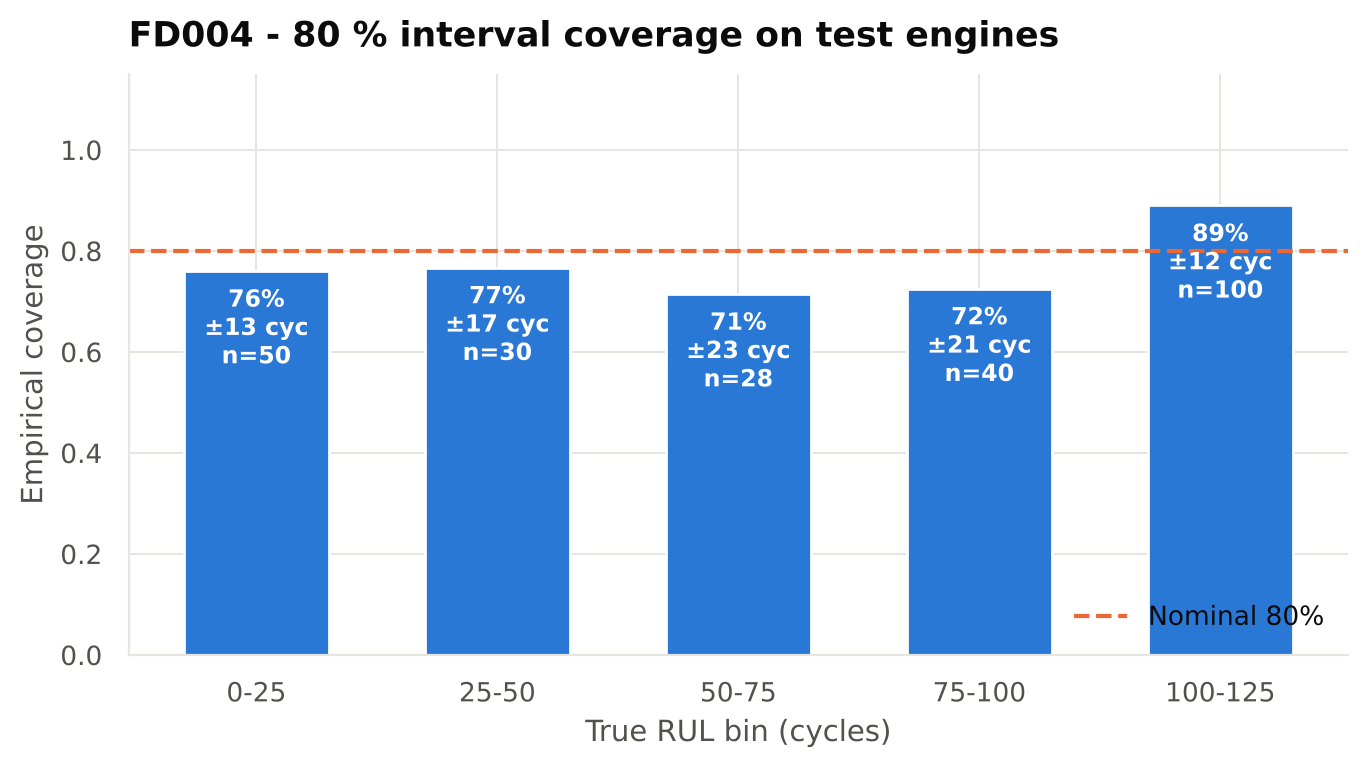

In [8]:
unc = pd.DataFrame({d: {"raw quantile coverage (val)": s["metadata"]["raw_interval_coverage"],
                         "conformal correction (cycles)": s["metadata"]["conformal_correction"],
                         "test coverage": s["test"]["coverage"], "test mean width": s["test"]["mean_width"],
                         "isotonic adopted": s["metadata"]["isotonic_enabled"]} for d, s in summary.items()}).T
display(unc)
display(Image(FIG / "FD004_interval_coverage.png", width=620))

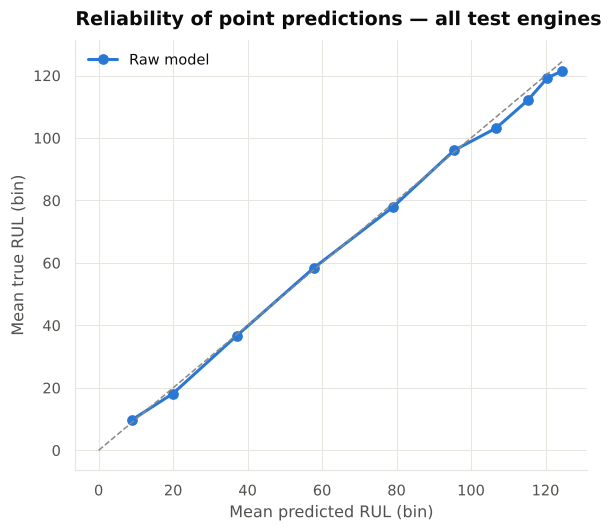

In [9]:
frames = []
for d in summary:
    p = pd.read_csv(ROOT / "data" / "processed" / f"{d}_test_predictions.csv"); p["dataset"] = d; frames.append(p)
allp = pd.concat(frames)
fig = viz.plot_reliability(allp["rul_true"], allp["rul_pred"], title="Reliability of point predictions — all test engines")
viz.save_figure(fig, "reliability_all", FIG); plt.show()

Point predictions follow the diagonal closely; the residual flattening at the top is the 125-cycle cap. The isotonic recalibrator is adopted only if engine-grouped CV on the calibration set shows a real gain — it was **not adopted on any scenario** (it would have added variance without removing bias).

Interval coverage on the test sets is 80–83 % for FD001, FD002, FD004 and 74 % for FD003. The conformal guarantee is *marginal* and was calibrated on only 20 validation engines for FD001/FD003, so a few points of deviation on a 100-engine test set are expected sampling noise. Coverage per life-stage bin varies between 63 % and 95 % with no consistent pattern across datasets — the marginal guarantee holds on average, not per stage. Mondrian (stage-conditional) conformal prediction would equalise it. Interval half-widths adapt to the stage: about ± 5 cycles near failure, ± 20 cycles mid-life.

## 5. Online behaviour on held-out engines

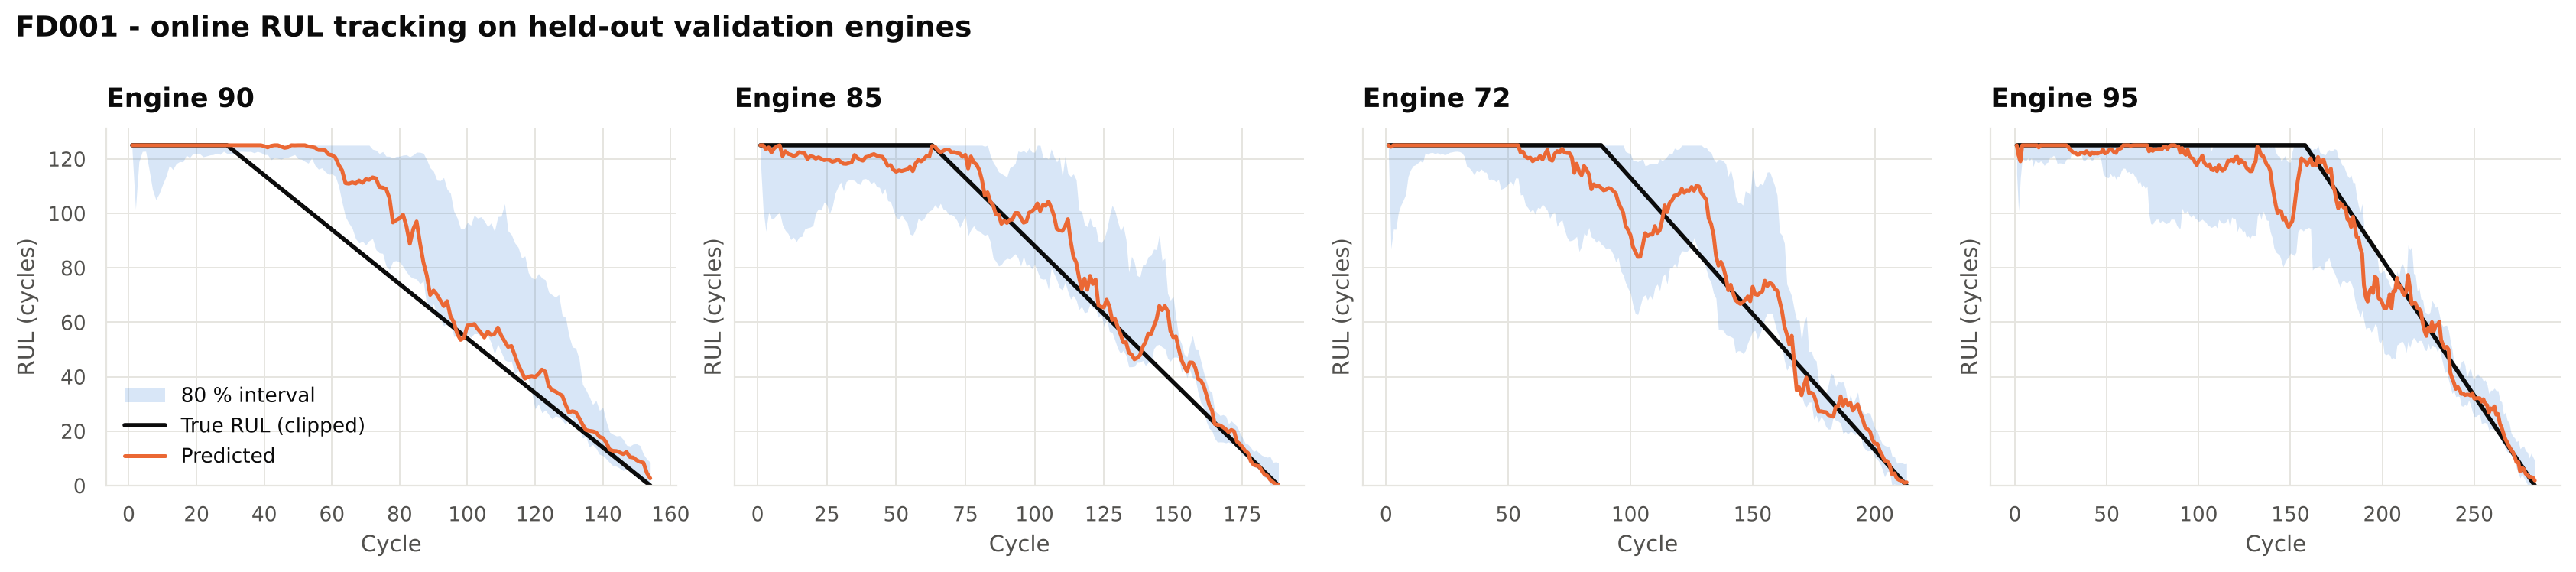

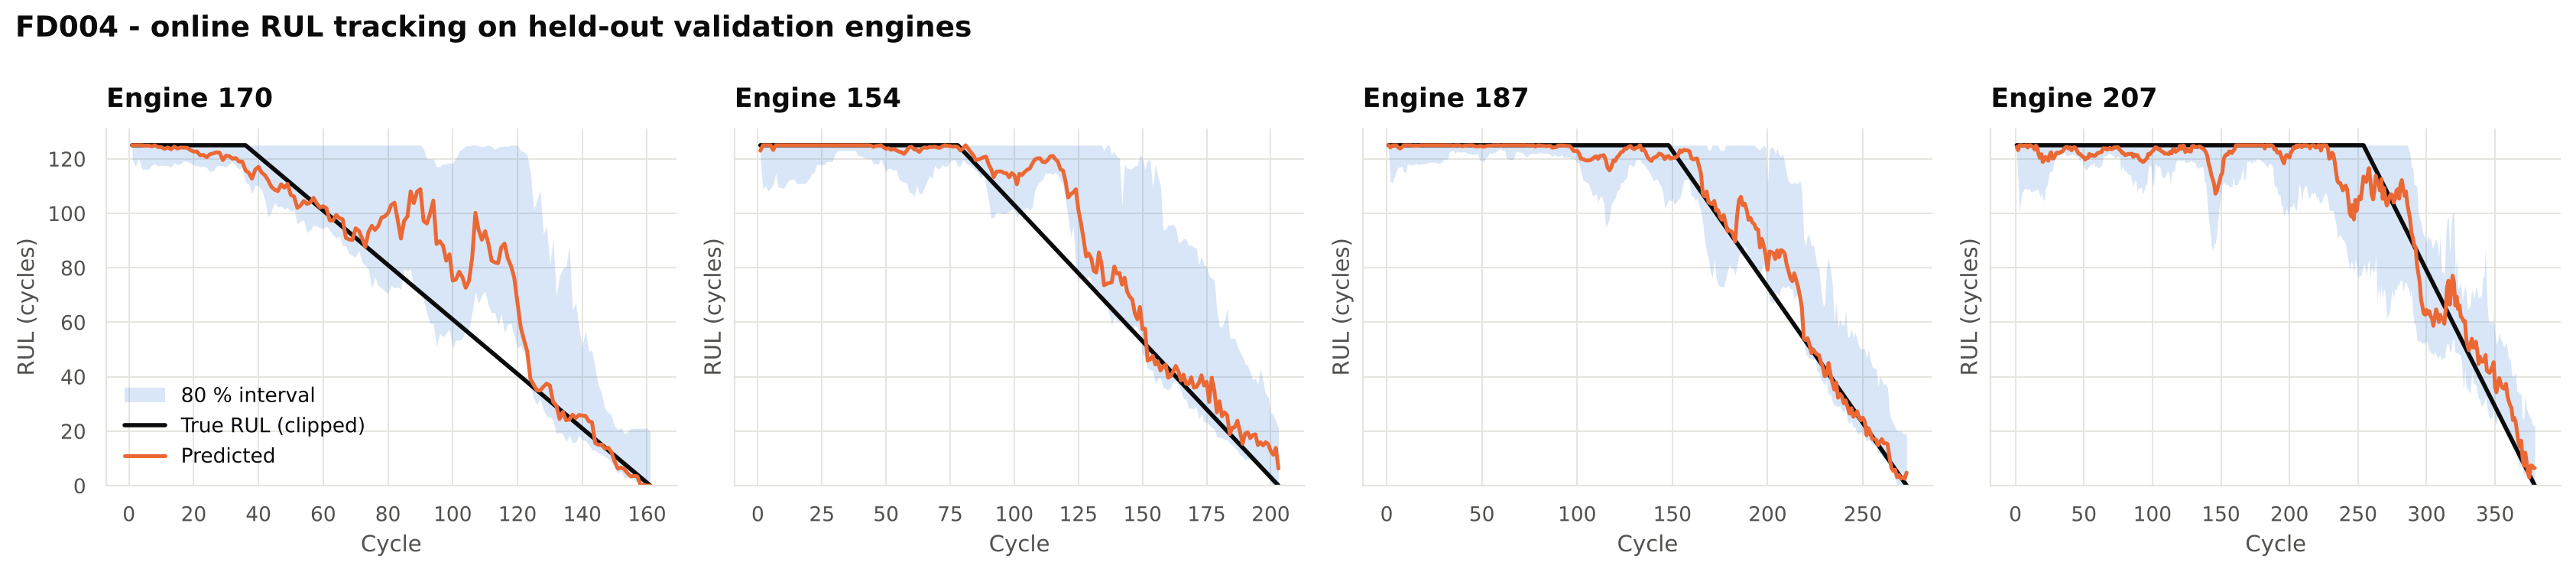

In [10]:
display(Image(FIG / "FD001_validation_trajectories.png", width=1000))
display(Image(FIG / "FD004_validation_trajectories.png", width=1000))

The estimate stays at the 125-cycle plateau while the engine is healthy, then follows the true RUL as degradation becomes observable, and the interval tightens as failure approaches — exactly the behaviour a maintenance planner needs: **few false alarms early, sharp information late.**

## 6. Business impact

Policies are simulated on all held-out run-to-failure validation engines of the four scenarios, with a 10-cycle logistics lead time (an alarm at cycle *t* removes the engine at *t* + 10; failure inside that window counts as unplanned). Economic parameters (`config.yaml > business`) are **illustrative**: an unplanned event at 6× a planned shop visit, plus the value of discarded useful life.

,policy,engines,unplanned_failures,failure_rate,mean_wasted_cycles,cost_per_engine,total_cost,savings_vs_reactive
20,Reactive (run-to-failure),142,142,1.000,0.000,"$1,500,000","$213,000,000",0.000
21,Fixed interval (127 cycles),142,0,0.000,96.866,"$366,239","$52,006,000",0.756
22,Predictive - point estimate,142,20,0.141,4.761,"$431,769","$61,311,200",0.712
23,Predictive - risk-aware (lower bound),142,0,0.000,9.289,"$261,146","$37,082,800",0.826
24,Oracle (perfect RUL),142,0,0.000,0.000,"$250,000","$35,500,000",0.833


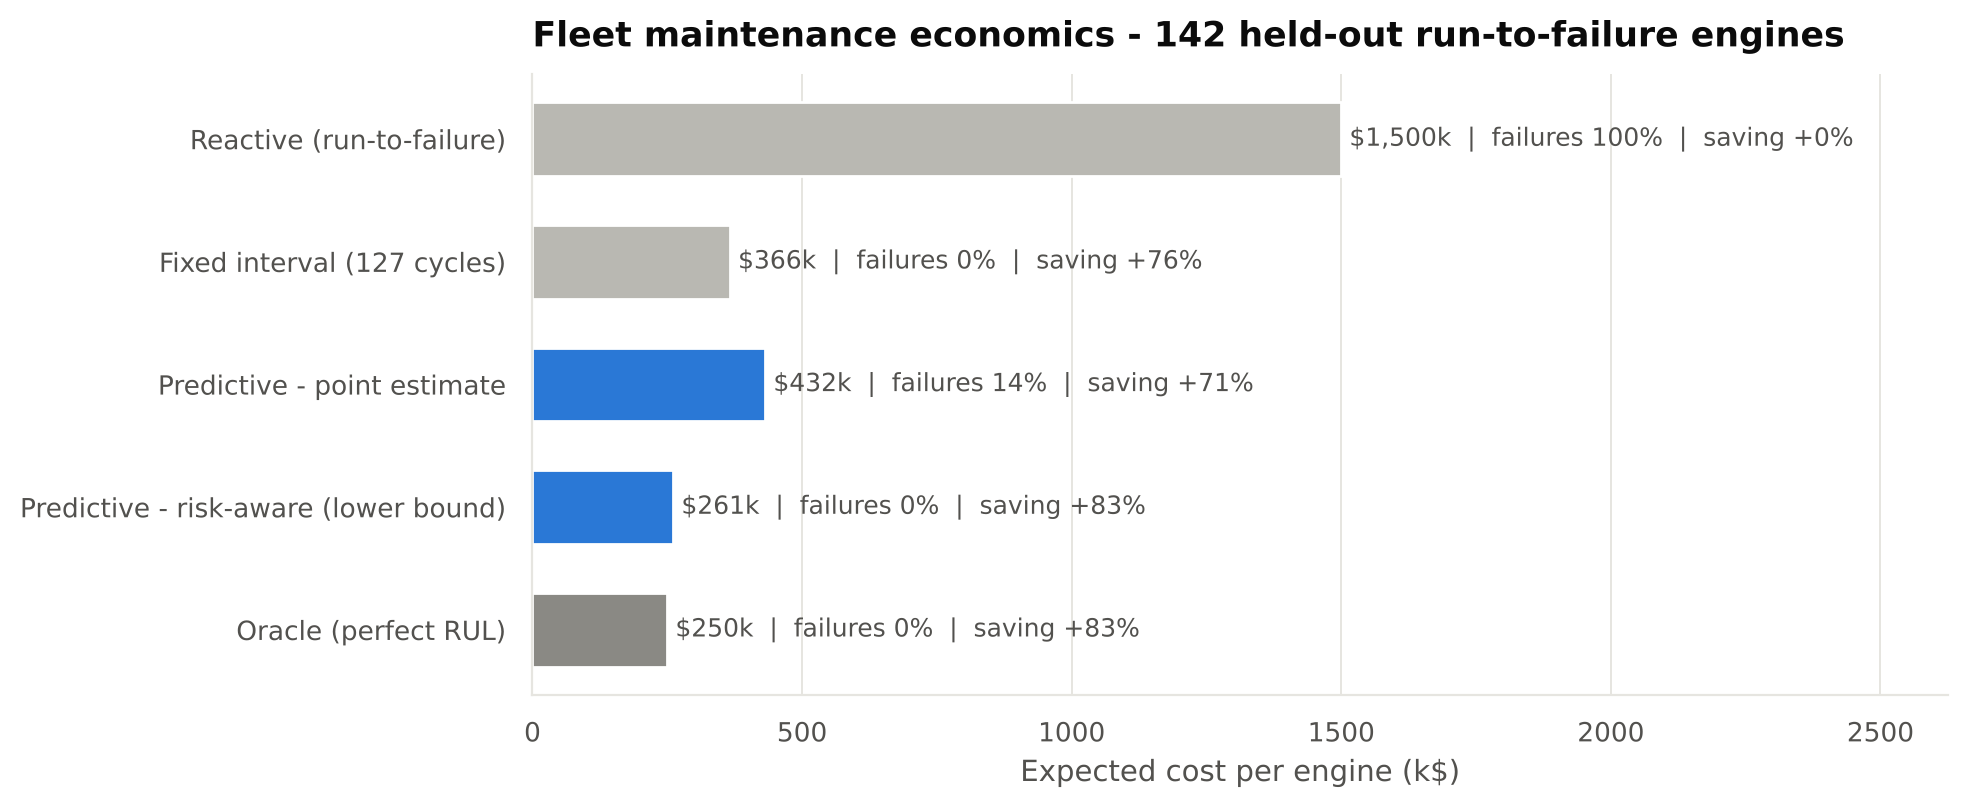

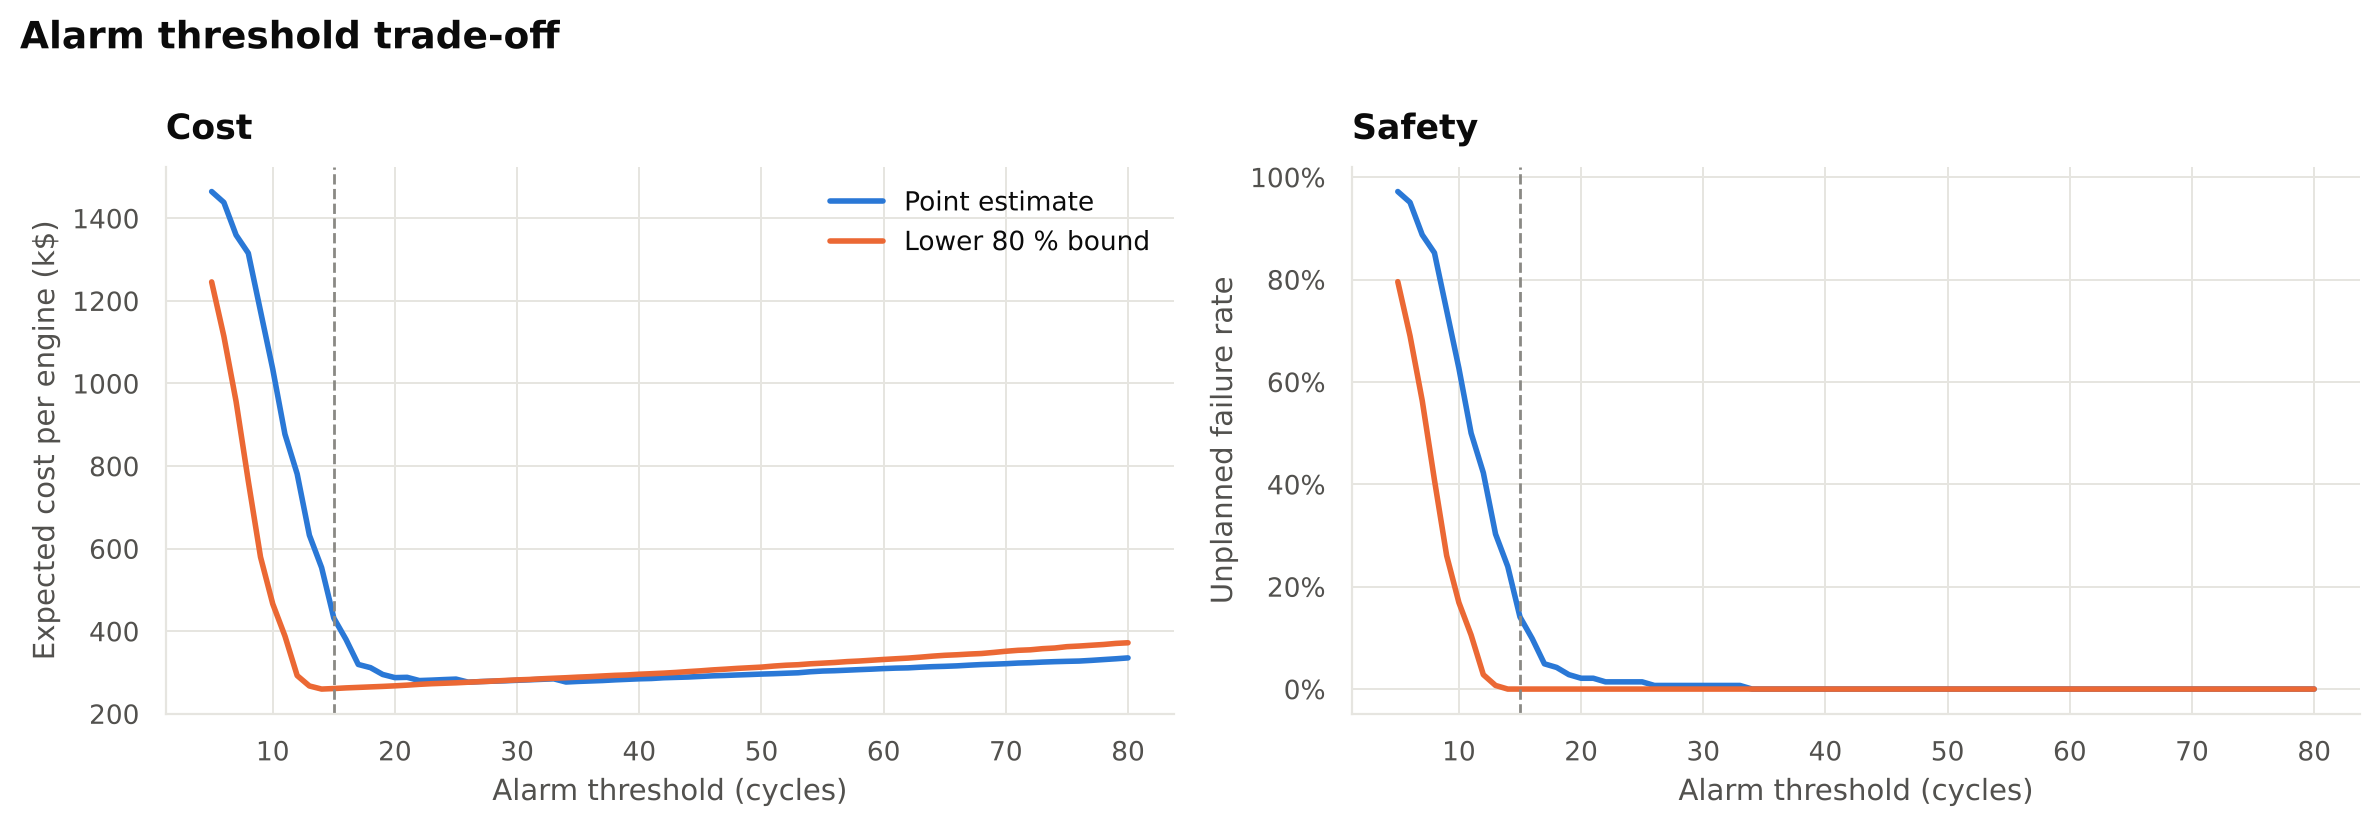

In [11]:
fleet = policies[policies.dataset == "FLEET"].drop(columns="dataset")
display(fleet.assign(cost_per_engine=lambda d: d.cost_per_engine.map("${:,.0f}".format),
                     total_cost=lambda d: d.total_cost.map("${:,.0f}".format)).round(3))
display(Image(FIG / "fleet_policy_costs.png", width=900))
display(Image(FIG / "fleet_threshold_sweep.png", width=950))

### Sensitivity to the cost of an unplanned failure

The ranking of strategies should not hinge on one assumed number. Re-running the simulation for a range of failure-to-planned cost ratios:

00:39:24 | INFO    | src.data.load_data | Loaded FD001: 100 train engines (20631 rows), 100 test engines (13096 rows)


00:39:25 | INFO    | src.data.load_data | Loaded FD002: 260 train engines (53759 rows), 259 test engines (33991 rows)


00:39:25 | INFO    | src.data.load_data | Loaded FD003: 100 train engines (24720 rows), 100 test engines (16596 rows)


00:39:26 | INFO    | src.data.load_data | Loaded FD004: 249 train engines (61249 rows), 248 test engines (41214 rows)


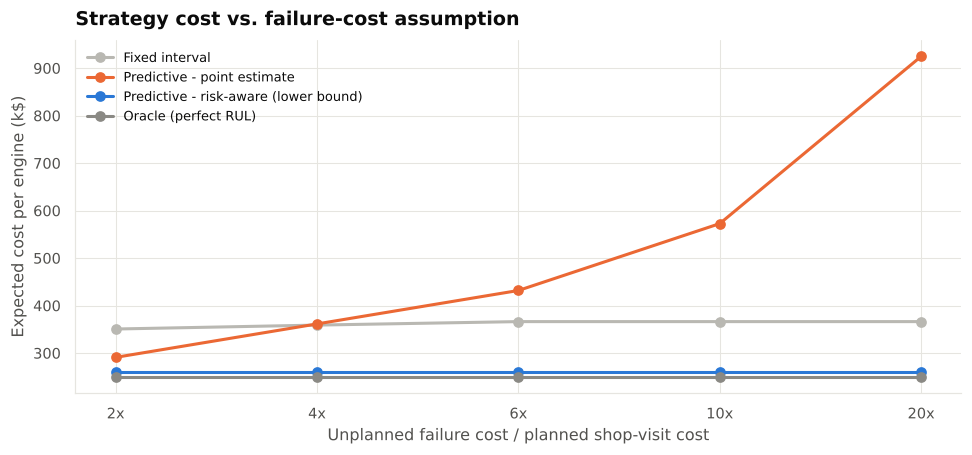

,Reactive (run-to-failure),Fixed interval,Predictive - point estimate,Predictive - risk-aware (lower bound),Oracle (perfect RUL)
2x,500.0,351.0,291.0,261.0,250.0
4x,1000.0,359.0,361.0,261.0,250.0
6x,1500.0,366.0,432.0,261.0,250.0
10x,2500.0,366.0,573.0,261.0,250.0
20x,5000.0,366.0,925.0,261.0,250.0


In [12]:
import copy
from src.models.evaluate import compare_policies
traj = pd.concat([pd.read_parquet(ROOT / "data" / "processed" / f"{d}_validation_trajectories.parquet")
                  .assign(unit=lambda x, d=d: d + "-" + x["unit"].astype(str)) for d in summary])
lifetimes = []
for d in summary:
    t, _ = split_engines(add_train_rul(load_dataset(d, ROOT / cfg["paths"]["raw_dir"]).train, MAX_RUL), 0.2, SEED)
    lifetimes.append(t.groupby("unit")["cycle"].max().to_numpy())
lifetimes = np.concatenate(lifetimes)
rows = []
for ratio in [2, 4, 6, 10, 20]:
    c = copy.deepcopy(cfg); c["business"]["unplanned_failure_cost"] = ratio * c["business"]["planned_maintenance_cost"]
    res = compare_policies(traj, lifetimes, c).set_index("policy")["cost_per_engine"]
    res.index = [i.split(" (")[0] if i.startswith("Fixed") else i for i in res.index]
    rows.append(res.rename(f"{ratio}x"))
sens = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 4.3))
for i, col in enumerate([c for c in sens.columns if not c.startswith("Reactive")]):
    ax.plot(sens.index, sens[col] / 1e3, marker="o", color=["#b9b8b2", viz.PALETTE[1], viz.PALETTE[0], viz.INK_3][i], label=col)
ax.set(xlabel="Unplanned failure cost / planned shop-visit cost", ylabel="Expected cost per engine (k$)",
       title="Strategy cost vs. failure-cost assumption"); ax.legend(fontsize=8.5)
fig.tight_layout(); viz.save_figure(fig, "cost_sensitivity", FIG); plt.show()
(sens / 1e3).round(0)

**Conclusions**

* The **risk-aware predictive policy** (alarm on the lower bound of the 80 % interval) is the cheapest realistic strategy at every cost ratio and stays close to the oracle.
* Acting on the **point estimate** alone leaves 14 % unplanned failures (the estimate is late for some engines). It beats fixed-interval maintenance only when a failure costs ~2× a shop visit; from 4× upward its failures make it the worst non-reactive option — this is the quantitative argument for uncertainty estimation.
* **Is the interval really needed, or just a higher threshold?** The threshold sweep answers it: acting on the point estimate reaches zero failures only from a 34-cycle threshold (cost ≈ $277k per engine, ~15 wasted cycles), whereas the lower bound reaches it at 14 cycles (≈ $260k, ~8 wasted cycles). A well-tuned point-estimate policy closes most of the gap, but the interval-based policy stays ~6 % cheaper, wastes half as much life and is safe without fleet-specific threshold tuning — the interval adapts its margin engine by engine, a fixed threshold cannot.
* The fixed-interval policy is safe but discards a large share of useful life, because it must protect the shortest-lived engines of the fleet.